The below md cell is thought and designed before performing this experiment, assisted by ChatGPT. I will delete it after my experiment completes..

# 04 — BTL, Full CDM and Low-Rank CDM on Common Synthetic Data

## Main question

Jab choices BTL, full CDM ya low-rank CDM se generate hoti hain,
toh same training data par fitted BTL, full CDM aur low-rank CDM
unseen choices ko kitna achha predict karte hain?

## Models to fit on every dataset

- BTL/Luce
- Full CDM
- Low-rank CDM: ranks 1, 2 and 3

Every model gets exactly the same train, validation and test observations.

## Three data-generating settings

1. BTL truth:
   Generate choices from a known BTL/Luce parameter vector.
   Include both pairs and triples; the existing pairwise generator alone
   is insufficient for this notebook.

2. Full-CDM truth:
   Start with a nonuniform BTL-like preference pattern and add genuine
   context interactions. At zero context strength, the generator should
   reproduce BTL probabilities on both pairs and triples.

3. Rank-2 CDM truth:
   Generate interactions using known target and context vectors.
   Check whether fitted rank 2 does well, and what happens when we fit
   rank 1, rank 3 and full CDM to the same data.

## Rough settings

- Pilot: n=10, m=5_000, one seed; inspect the complete pipeline.
- Main comparison: n=[10, 20], m=50_000, around 5 independent runs.
- n=40: add only after checking main-run results and runtime.
- Choice-set sizes: (2, 3), with a fixed and reported proportion.
- Base seed: 20260831; log generation, split and optimizer seeds separately.
- Use CPU and torch.float64 initially, consistent with earlier CDM notebooks.
- Split data into train/validation/test; choose rank and optimizer settings
  using validation data, then report test results once.

## Measurements

- Average train, validation and test NLL for every fitted model.
- True generating model's test NLL as an oracle reference.
- Test NLL separately for pair choices and triple choices.
- Parameter RMSE only when comparing compatible, identifiable parameters:
  BTL parameters under BTL truth; off-diagonal CDM interactions under
  CDM truth. Do not compare BTL parameters directly with a CDM matrix.
- Runtime, epochs/updates, final training NLL and stopping reason.
- For low-rank CDM, compare its interaction matrix, not raw target/context
  vectors: different vector representations can produce the same interactions.

## Figures

1. Test NLL of fitted BTL, full CDM and ranks 1/2/3 under each truth.
2. Train versus test NLL: where does extra flexibility help or overfit?
3. Test NLL versus n for the selected generating settings.
4. One direct context example: compare odds of choosing i over j in
   {i, j} versus {i, j, k}. BTL keeps the odds unchanged; a CDM can change them.
5. Rank versus validation/test NLL under rank-2 truth.

## Interpretation questions

- Under BTL truth, does extra CDM flexibility improve prediction,
  make no difference, or overfit?
- Under full-CDM truth, how much does BTL lose on unseen choices?
- Under rank-2 truth, can a compact model match or beat the full CDM?
- Does the best rank change when n changes?
- Are any apparent differences consistent across independent runs?

## Boundary of this notebook

This notebook establishes the shared comparison pipeline and introduces
low-rank CDM. Detailed sweeps over m, sampling schemes and optimizers
belong in Notebook 05. Pairwise-only CDM fitting stays a separate
non-identifiability diagnostic, not the main comparison here.

Reusable generation, fitting and evaluation functions go in src/.
The notebook contains settings, experiment calls, tables, plots and
short conclusions in my own words.

## <span style="color:#1F4E79;">**Unified Synthetic Choice-Model Experiment**</span>
- Use one common setting for BTL-generated and CDM-generated data:
  same number of items, observations, sampled choice sets, split and seed plan.
- Generate both datasets together, then fit each dataset with:
  Choix BTL/Luce and PyTorch full CDM.
- This gives four comparisons in one experiment:
  BTL→BTL, BTL→CDM, CDM→BTL and CDM→CDM.
- Add PyTorch low-rank CDM fits to the same datasets and splits.
- Show the models' results together in one comparison table and
  side-by-side plots. Compare test NLL for all fits, and parameter
  recovery only where the parameters are comparable.

In [16]:
import numpy as np
import pandas as pd
import torch
from time import perf_counter
from matplotlib import pyplot as plt
from pathlib import Path
import json
SEED = 20260831
N_ITEMS = 10
N_OBSERVATIONS = 10_000
SET_SIZE_PROBABILITIES = {2: 0.5, 3: 0.5}
SPLIT_FRACTIONS = {"train": 0.70, "validation": 0.15, "test": 0.15}
PARAMETER_SCALE = 0.4
DEVICE = torch.device("cpu")
DTYPE = torch.float64

pd.Series({
    "Items": N_ITEMS,
    "Observations per generated dataset": N_OBSERVATIONS,
    "Choice-set sizes": SET_SIZE_PROBABILITIES,
    "Split": SPLIT_FRACTIONS,
    "Seed": SEED,
    "Device": str(DEVICE),
    "PyTorch dtype": str(DTYPE),
}, name="Setting")
from bradley_terry import *
from context_dependent_model import *

| Package | Name | Purpose  |
|---|---|---|
| BTL | `center_parameters` | Centers BTL item parameters so their mean is zero. |
| BTL | `estimate_top1_parameters_with_choix` | Fits BTL with Choix using the chosen item from each choice set, including pairs and triples. |
| BTL | `average_top1_negative_log_likelihood` | Computes average BTL negative log-likelihood, especially on test data. |
| BTL | `parameter_recovery_error` | Computes RMSE between true and fitted BTL parameters. |
| CDM | `generate_cdm_parameters` | Creates the true interaction matrix for synthetic CDM data. |
| CDM | `generate_uniform_choice_sets` | Samples choice sets that we can share between both data generators. |
| CDM | `cdm_choice_probabilities` | Computes CDM choice probabilities for those sets. |
| CDM | `CDMChoiceData` | Holds choice sets, masks, and observed choices. This is a class, not a function. |
| CDM | `optimize_full_cdm_with_adam` | Fits the full CDM using PyTorch and Adam. |
| CDM | `average_cdm_negative_log_likelihood` | Computes average CDM negative log-likelihood, especially on test data. |
| CDM | `center_cdm_parameters` | Sets the interaction matrix diagonal to zero and centers its other entries. |
| CDM | `cdm_parameter_recovery_error` | Computes RMSE between true and fitted CDM interactions. |
| CDM | `generate_cdm_choice_data` | Generates CDM data, but samples its own choice sets; it cannot directly reuse our shared sets. |
| CDM | `split_cdm_choice_data` | Makes a train/test split; it does not currently provide a validation split. |

In [17]:
for name in (
    "choice_sets",
    "choice_mask",
    "shared_choice_sets",
    "btl_observations",
    "cdm_choice_data",
):
    print(name, name in globals())

choice_sets True
choice_mask True
shared_choice_sets True
btl_observations True
cdm_choice_data True


In [18]:
# Set up this run's directories and save its settings.
PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "docs" / "thesis" / "images").is_dir()
)
RUN_ID = f"n{N_ITEMS}_m{N_OBSERVATIONS}_seed{SEED}_scale{PARAMETER_SCALE:g}"

FIGURE_DIR = PROJECT_ROOT / "docs/thesis/images/experiments/context_dependent_model/unified" / RUN_ID
TABLE_DIR = PROJECT_ROOT / "docs/thesis/tables/experiments/context_dependent_model/unified" / RUN_ID
LOG_DIR = PROJECT_ROOT / "results/experiments/04_unified_synthetic" / RUN_ID

for folder in (FIGURE_DIR, TABLE_DIR, LOG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

settings = {
    "n_items": N_ITEMS,
    "observations_per_dataset": N_OBSERVATIONS,
    "parameter_scale": PARAMETER_SCALE,
    "set_size_probabilities": SET_SIZE_PROBABILITIES,
    "split_fractions": SPLIT_FRACTIONS,
    "seed": SEED,
    "device": str(DEVICE),
    "dtype": str(DTYPE),
}
(LOG_DIR / "settings.json").write_text(
    json.dumps(settings, indent=2), encoding="utf-8"
)

298

In [19]:
# Generate BTL and CDM choices on the same sampled choice sets.
PARAMETER_SCALE = 0.4

true_btl_parameters = center_parameters(
    np.random.default_rng(SEED).normal(0, PARAMETER_SCALE, N_ITEMS)
)
true_cdm_parameters = generate_cdm_parameters(
    N_ITEMS, parameter_scale=PARAMETER_SCALE,
    random_seed=SEED + 1, device=DEVICE, dtype=DTYPE,
)

choice_sets, choice_mask = generate_uniform_choice_sets(
    N_ITEMS, N_OBSERVATIONS, tuple(SET_SIZE_PROBABILITIES),
    random_seed=SEED + 2, device=DEVICE,
)
shared_choice_sets = [
    tuple(row[mask].tolist())
    for row, mask in zip(choice_sets, choice_mask)
]

btl_observations = generate_top1_choice_data_on_sets(
    true_btl_parameters, shared_choice_sets,
    np.random.default_rng(SEED + 3),
)
btl_choice_data = CDMChoiceData(
    choice_sets=choice_sets,
    choice_mask=choice_mask,
    chosen_positions=torch.tensor(
        [items.index(winner) for winner, items in btl_observations],
        dtype=torch.long, device=DEVICE,
    ),
)

cdm_choice_data = generate_cdm_choice_data_on_sets(
    true_cdm_parameters, choice_sets, choice_mask,
    random_seed=SEED + 4,
)
cdm_observations = list(zip(
    cdm_choice_data.chosen_items.cpu().tolist(),
    shared_choice_sets,
))

pd.DataFrame({
    "Choice set": shared_choice_sets[:5],
    "BTL choice": [winner for winner, _ in btl_observations[:5]],
    "CDM choice": cdm_choice_data.chosen_items[:5].cpu().tolist(),
})

,Choice set,BTL choice,CDM choice
0,"(7, 9)",7,9
1,"(1, 3)",1,1
2,"(2, 9, 1)",2,1
3,"(4, 3)",4,3
4,"(7, 3, 5)",7,3


In [20]:
# Give both datasets the same train, validation, and test row indices.
shuffled = np.random.default_rng(SEED + 5).permutation(N_OBSERVATIONS)
n_train = int(N_OBSERVATIONS * SPLIT_FRACTIONS["train"])
n_validation = int(N_OBSERVATIONS * SPLIT_FRACTIONS["validation"])

split_indices = {
    "train": shuffled[:n_train],
    "validation": shuffled[n_train:n_train + n_validation],
    "test": shuffled[n_train + n_validation:],
}

split_data = {}
for source, (observations, data) in {
    "BTL": (btl_observations, btl_choice_data),
    "CDM": (cdm_observations, cdm_choice_data),
}.items():
    split_data[source] = {}
    for split_name, indices in split_indices.items():
        tensor_indices = torch.as_tensor(indices, dtype=torch.long, device=DEVICE)
        split_data[source][split_name] = {
            "choix": [observations[i] for i in indices],
            "torch": CDMChoiceData(
                choice_sets=data.choice_sets[tensor_indices],
                choice_mask=data.choice_mask[tensor_indices],
                chosen_positions=data.chosen_positions[tensor_indices],
            ),
        }

split_labels = np.empty(N_OBSERVATIONS, dtype=object)
for split_name, indices in split_indices.items():
    split_labels[indices] = split_name

pd.DataFrame({
    "observation_id": np.arange(N_OBSERVATIONS),
    "split": split_labels,
}).to_csv(LOG_DIR / "split_assignment.csv", index=False)

pd.DataFrame({
    "Split": list(split_indices),
    "Observations per dataset": [len(indices) for indices in split_indices.values()],
})

,Split,Observations per dataset
0,train,7000
1,validation,1500
2,test,1500


In [21]:
# Save the choices and true parameters after they have been generated.
# for overleaf
pd.DataFrame({
    "choice_set": [json.dumps(items) for items in shared_choice_sets],
    "set_size": [len(items) for items in shared_choice_sets],
    "btl_choice": [winner for winner, _ in btl_observations],
    "cdm_choice": cdm_choice_data.chosen_items.cpu().tolist(),
}).to_csv(LOG_DIR / "generated_choices.csv", index=False)

pd.Series(true_btl_parameters, name="parameter").rename_axis("item").to_csv(
    LOG_DIR / "true_btl_parameters.csv"
)
pd.DataFrame(true_cdm_parameters.cpu().numpy()).rename_axis("target_item").to_csv(
    LOG_DIR / "true_cdm_parameters.csv"
)

display(pd.Series({
    "Figures": str(FIGURE_DIR),
    "Thesis tables": str(TABLE_DIR),
    "Data and settings": str(LOG_DIR),
}))

Figures              /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
Thesis tables        /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
Data and settings    /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
dtype: object

In [22]:
# Fit BTL and full CDM to each generated dataset; log fitted parameters.
fit_settings = {
    "btl_alpha": 0.0,
    "btl_max_iterations": 1000,
    "cdm_learning_rate": 0.05,
    "cdm_max_epochs": 2000,
}
(LOG_DIR / "fit_settings.json").write_text(
    json.dumps(fit_settings, indent=2), encoding="utf-8"
)

fit_results = {}
fit_records = []

for source in ("BTL", "CDM"):
    training = split_data[source]["train"]

    start = perf_counter()
    btl_fit = estimate_top1_parameters_with_choix(
        N_ITEMS, training["choix"],
        alpha=fit_settings["btl_alpha"],
        maximum_iterations=fit_settings["btl_max_iterations"],
    )
    btl_seconds = perf_counter() - start

    start = perf_counter()
    cdm_fit = optimize_full_cdm_with_adam(
        N_ITEMS, training["torch"],
        learning_rate=fit_settings["cdm_learning_rate"],
        maximum_epochs=fit_settings["cdm_max_epochs"],
        dtype=DTYPE,
    )
    cdm_seconds = perf_counter() - start

    fit_results[source] = {"BTL": btl_fit, "CDM": cdm_fit}
    fit_records.extend([
        {"Data": source, "Fit": "BTL", "Seconds": btl_seconds,
         "Epochs": None, "Converged": None},
        {"Data": source, "Fit": "CDM", "Seconds": cdm_seconds,
         "Epochs": cdm_fit.epochs_completed, "Converged": cdm_fit.converged},
    ])

    pd.Series(btl_fit, name="fitted_parameter").rename_axis("item").to_csv(
        LOG_DIR / f"{source.lower()}_btl_fit.csv"
    )
    pd.DataFrame(cdm_fit.interaction_matrix.cpu().numpy()).rename_axis(
        "target_item"
    ).to_csv(LOG_DIR / f"{source.lower()}_cdm_fit.csv")

    pd.DataFrame({
        "epoch": range(len(cdm_fit.nll_history)),
        "train_nll": cdm_fit.nll_history,
        "gradient_norm": [np.nan, *cdm_fit.gradient_norm_history],
    }).to_csv(LOG_DIR / f"{source.lower()}_cdm_training_history.csv", index=False)

fit_summary = pd.DataFrame(fit_records)
fit_summary.to_csv(LOG_DIR / "fit_diagnostics.csv", index=False)
fit_summary

,Data,Fit,Seconds,Epochs,Converged
0,BTL,BTL,0.092787,NaN,None
1,BTL,CDM,1.375190,170.0,True
2,CDM,BTL,0.093723,NaN,None
3,CDM,CDM,0.305316,158.0,True


In [23]:
# Compare all four fits on train, validation, and test observations.
comparison_rows = []

for source in ("BTL", "CDM"):
    for fitted_model in ("BTL", "CDM"):
        fit = fit_results[source][fitted_model]
        nll = {}

        for split_name in ("train", "validation", "test"):
            data = split_data[source][split_name]

            if fitted_model == "BTL":
                value = average_top1_negative_log_likelihood(
                    data["choix"], fit
                )
            else:
                torch_data = data["torch"]
                with torch.no_grad():
                    value = average_cdm_negative_log_likelihood(
                        fit.interaction_matrix,
                        torch_data.choice_sets,
                        torch_data.chosen_positions,
                        torch_data.choice_mask,
                    ).item()

            nll[f"{split_name.title()} NLL"] = value

        recovery_error = np.nan
        if source == "BTL" and fitted_model == "BTL":
            recovery_error = parameter_recovery_error(
                true_btl_parameters, fit
            )
        elif source == "CDM" and fitted_model == "CDM":
            recovery_error = cdm_parameter_recovery_error(
                true_cdm_parameters, fit.interaction_matrix
            )

        comparison_rows.append({
            "Experiment": f"{source} → {fitted_model}",
            **nll,
            "Recovery RMSE": recovery_error,
        })

comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(TABLE_DIR / "04_model_comparison.csv", index=False)
comparison_table.to_latex(
    TABLE_DIR / "04_model_comparison.tex",
    index=False, float_format="%.4f", na_rep="",
)

comparison_table.round(4)

,Experiment,Train NLL,Validation NLL,Test NLL,Recovery RMSE
0,BTL → BTL,0.8610,0.8673,0.8607,0.0374
1,BTL → CDM,0.8547,0.8742,0.8619,NaN
2,CDM → BTL,0.8908,0.8883,0.8804,NaN
3,CDM → CDM,0.8253,0.8217,0.8361,0.2095


In [24]:
# Give BTL→CDM its exact recovery target and check the CDM fit.
theta = torch.as_tensor(true_btl_parameters, dtype=DTYPE, device=DEVICE)
btl_truth_as_cdm = -theta.unsqueeze(0).repeat(N_ITEMS, 1)
btl_truth_as_cdm.fill_diagonal_(0)
btl_truth_as_cdm = center_cdm_parameters(btl_truth_as_cdm)

comparison_table["BTL parameter RMSE"] = np.nan
comparison_table["CDM interaction RMSE"] = np.nan

comparison_table.loc[
    comparison_table["Experiment"].eq("BTL → BTL"), "BTL parameter RMSE"
] = parameter_recovery_error(
    true_btl_parameters, fit_results["BTL"]["BTL"]
)
comparison_table.loc[
    comparison_table["Experiment"].eq("BTL → CDM"), "CDM interaction RMSE"
] = cdm_parameter_recovery_error(
    btl_truth_as_cdm, fit_results["BTL"]["CDM"].interaction_matrix
)
comparison_table.loc[
    comparison_table["Experiment"].eq("CDM → CDM"), "CDM interaction RMSE"
] = cdm_parameter_recovery_error(
    true_cdm_parameters, fit_results["CDM"]["CDM"].interaction_matrix
)

comparison_table = comparison_table.drop(columns=["Recovery RMSE"], errors="ignore")
comparison_table.to_csv(TABLE_DIR / "04_model_comparison.csv", index=False)
comparison_table.to_latex(
    TABLE_DIR / "04_model_comparison.tex",
    index=False, float_format="%.4f", na_rep="",
)

with torch.no_grad():
    btl_logits = theta[choice_sets.clamp_min(0)].masked_fill(
        ~choice_mask, -torch.inf
    )
    probability_difference = (
        torch.softmax(btl_logits, dim=1)
        - cdm_choice_probabilities(btl_truth_as_cdm, choice_sets, choice_mask)
    ).abs().max().item()

diagnostic_rows = []
for split_name in ("train", "test"):
    data = split_data["CDM"][split_name]["torch"]
    with torch.no_grad():
        losses = {
            label: average_cdm_negative_log_likelihood(
                matrix, data.choice_sets, data.chosen_positions, data.choice_mask
            ).item()
            for label, matrix in {
                "True CDM": true_cdm_parameters,
                "Fitted CDM": fit_results["CDM"]["CDM"].interaction_matrix,
            }.items()
        }
    diagnostic_rows.append({"Split": split_name, **losses})

diagnostic_table = pd.DataFrame(diagnostic_rows)
diagnostic_table.to_csv(LOG_DIR / "cdm_truth_vs_fit_nll.csv", index=False)

print(f"BTL/CDM probability difference: {probability_difference:.2e}")
print(
    "Zero-matrix CDM RMSE:",
    round(cdm_parameter_recovery_error(
        true_cdm_parameters, torch.zeros_like(true_cdm_parameters)
    ), 4),
)
display(comparison_table.round(4), diagnostic_table.round(4))

BTL/CDM probability difference: 1.11e-16
Zero-matrix CDM RMSE: 0.4312


,Experiment,Train NLL,Validation NLL,Test NLL,BTL parameter RMSE,CDM interaction RMSE
0,BTL → BTL,0.8610,0.8673,0.8607,0.0374,NaN
1,BTL → CDM,0.8547,0.8742,0.8619,NaN,0.1974
2,CDM → BTL,0.8908,0.8883,0.8804,NaN,NaN
3,CDM → CDM,0.8253,0.8217,0.8361,NaN,0.2095


,Split,True CDM,Fitted CDM
0,train,0.8310,0.8253
1,test,0.8261,0.8361


In [25]:
# Fixed held-out, per-choice NLL comparison for both cross cases.
per_choice_rows = []

for source in ("BTL", "CDM"):
    data = split_data[source]["test"]["torch"]
    sets = data.choice_sets.cpu().numpy()
    mask = data.choice_mask.cpu().numpy()
    positions = data.chosen_positions.cpu().numpy()
    row_numbers = np.arange(len(positions))

    # Choix-fitted BTL/Luce parameters; evaluate their probabilities per choice.
    btl_scores = np.asarray(fit_results[source]["BTL"])[np.maximum(sets, 0)]
    btl_scores = np.where(mask, btl_scores, -np.inf)
    btl_nll = np.logaddexp.reduce(btl_scores, axis=1) - btl_scores[
        row_numbers, positions
    ]

    # PyTorch-fitted CDM probabilities on those exact same choices.
    with torch.no_grad():
        cdm_logits = cdm_choice_utilities(
            fit_results[source]["CDM"].interaction_matrix,
            data.choice_sets,
            data.choice_mask,
        )
        cdm_nll = -torch.log_softmax(cdm_logits, dim=1)[
            torch.arange(len(positions), device=cdm_logits.device),
            data.chosen_positions,
        ].cpu().numpy()

    if source == "BTL":
        true_scores = np.asarray(true_btl_parameters)[np.maximum(sets, 0)]
        true_scores = np.where(mask, true_scores, -np.inf)
        truth_nll = np.logaddexp.reduce(true_scores, axis=1) - true_scores[
            row_numbers, positions
        ]
        native_nll, cross_nll = btl_nll, cdm_nll
    else:
        with torch.no_grad():
            true_logits = cdm_choice_utilities(
                true_cdm_parameters, data.choice_sets, data.choice_mask
            )
            truth_nll = -torch.log_softmax(true_logits, dim=1)[
                torch.arange(len(positions), device=true_logits.device),
                data.chosen_positions,
            ].cpu().numpy()
        native_nll, cross_nll = cdm_nll, btl_nll

    for index, size, chosen, native, cross, truth in zip(
        split_indices["test"],
        mask.sum(axis=1),
        data.chosen_items.cpu().numpy(),
        native_nll,
        cross_nll,
        truth_nll,
    ):
        per_choice_rows.append({
            "Source": source,
            "Test row": int(index),
            "Menu size": int(size),
            "Chosen item": int(chosen),
            "Native fitted NLL": float(native),
            "Cross fitted NLL": float(cross),
            "True model NLL": float(truth),
            "Cross - native": float(cross - native),
            "Cross - truth": float(cross - truth),
        })

per_choice_nll = pd.DataFrame(per_choice_rows)
nll_columns = [
    "Native fitted NLL", "Cross fitted NLL", "True model NLL",
    "Cross - native", "Cross - truth",
]

by_size = per_choice_nll.groupby(["Source", "Menu size"], as_index=False).agg(
    Choices=("Test row", "size"),
    **{column: (column, "mean") for column in nll_columns},
)
overall = per_choice_nll.groupby("Source", as_index=False).agg(
    Choices=("Test row", "size"),
    **{column: (column, "mean") for column in nll_columns},
)
overall["Menu size"] = "All"
misspecification_summary = pd.concat(
    [overall[by_size.columns], by_size], ignore_index=True
)

LOG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
per_choice_nll.to_csv(LOG_DIR / "04_per_choice_test_nll.csv", index=False)
misspecification_summary.to_csv(
    TABLE_DIR / "04_cross_fit_test_nll.csv", index=False
)

display(misspecification_summary.round(4), per_choice_nll.head(8).round(4))

,Source,Menu size,Choices,Native fitted NLL,Cross fitted NLL,True model NLL,Cross - native,Cross - truth
0,BTL,All,1500,0.8607,0.8619,0.8602,0.0012,0.0017
1,CDM,All,1500,0.8361,0.8804,0.8261,0.0443,0.0543
2,BTL,2,759,0.6753,0.6749,0.6747,-0.0004,0.0002
3,BTL,3,741,1.0506,1.0534,1.0501,0.0029,0.0033
4,CDM,2,759,0.6630,0.6831,0.6574,0.0202,0.0257
5,CDM,3,741,1.0134,1.0825,0.9989,0.0691,0.0836


,Source,Test row,Menu size,Chosen item,Native fitted NLL,Cross fitted NLL,True model NLL,Cross - native,Cross - truth
0,BTL,6293,2,6,0.6207,0.7222,0.6488,0.1015,0.0734
1,BTL,5293,2,9,0.7557,0.6454,0.7934,-0.1103,-0.1480
2,BTL,4385,3,3,0.4523,0.4343,0.4669,-0.0180,-0.0325
3,BTL,2968,2,1,0.7429,0.7556,0.6939,0.0127,0.0617
4,BTL,5433,2,6,0.4542,0.4331,0.4739,-0.0211,-0.0408
5,BTL,5658,3,8,1.3240,1.4733,1.3261,0.1493,0.1472
6,BTL,7414,3,6,0.9989,0.7864,1.0020,-0.2125,-0.2156
7,BTL,32,3,3,0.6666,0.6430,0.6767,-0.0237,-0.0337


In the upper table for 3rd index row, the menu size 3, we can see that for native fitted ones is lower than cross fitted, maybe have to see and try out for different seeds or different runs and then see how are the results there..

Here Menu: All is the average of all held out test choices

In [26]:
# Record the fitting times already measured for all four experiments.
runtime_log = fit_summary.rename(
    columns={
        "Data": "Data source",
        "Fit": "Model",
        "Seconds": "Elapsed seconds",
    }
).copy()

runtime_log.insert(0, "Stage", "Fit")
runtime_log["Seed"] = SEED
runtime_log["Items"] = N_ITEMS
runtime_log["Training choices"] = len(split_indices["train"])
runtime_log["Free parameters"] = runtime_log["Model"].map({
    "BTL": N_ITEMS - 1,
    "CDM": N_ITEMS * (N_ITEMS - 1) - 1,
})
runtime_log["Device"] = runtime_log["Model"].map({
    "BTL": "CPU (Choix)",
    "CDM": str(DEVICE),
})

LOG_DIR.mkdir(parents=True, exist_ok=True)
runtime_log.to_csv(LOG_DIR / "04_runtime_log.csv", index=False)

display(runtime_log.round(4))

,Stage,Data source,Model,Elapsed seconds,Epochs,Converged,Seed,Items,Training choices,Free parameters,Device
0,Fit,BTL,BTL,0.0928,NaN,None,20260831,10,7000,9,CPU (Choix)
1,Fit,BTL,CDM,1.3752,170.0,True,20260831,10,7000,89,cpu
2,Fit,CDM,BTL,0.0937,NaN,None,20260831,10,7000,9,CPU (Choix)
3,Fit,CDM,CDM,0.3053,158.0,True,20260831,10,7000,89,cpu


Logging time as well for further future experiments, to get some insights while trying out Low-rank CDM.

,Source,Group,mean,std,choices,SE,95% lower,95% upper
0,BTL,All,0.0012,0.1160,1500,0.0030,-0.0047,0.0071
1,BTL,Pairs,-0.0004,0.0813,759,0.0029,-0.0062,0.0054
2,BTL,Triples,0.0029,0.1432,741,0.0053,-0.0074,0.0132
3,CDM,All,0.0443,0.3500,1500,0.0090,0.0266,0.0620
4,CDM,Pairs,0.0202,0.2835,759,0.0103,-0.0000,0.0403
5,CDM,Triples,0.0691,0.4057,741,0.0149,0.0398,0.0983


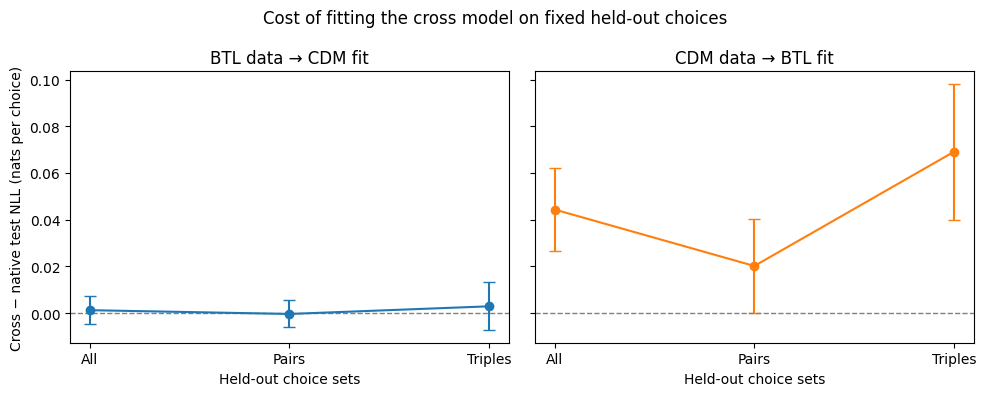

In [27]:
started_at = perf_counter()

# Each difference compares two fits on the same observed test choice.
gap_data = pd.concat(
    [
        per_choice_nll.assign(Group="All"),
        per_choice_nll.assign(
            Group=per_choice_nll["Menu size"].map({2: "Pairs", 3: "Triples"})
        ),
    ],
    ignore_index=True,
)

gap_summary = (
    gap_data.groupby(["Source", "Group"])["Cross - native"]
    .agg(mean="mean", std="std", choices="count")
    .reset_index()
)
gap_summary["SE"] = gap_summary["std"] / np.sqrt(gap_summary["choices"])
gap_summary["95% lower"] = gap_summary["mean"] - 1.96 * gap_summary["SE"]
gap_summary["95% upper"] = gap_summary["mean"] + 1.96 * gap_summary["SE"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, source, title, color in zip(
    axes,
    ("BTL", "CDM"),
    ("BTL data → CDM fit", "CDM data → BTL fit"),
    ("tab:blue", "tab:orange"),
):
    rows = gap_summary[gap_summary["Source"] == source].set_index("Group")
    rows = rows.loc[["All", "Pairs", "Triples"]]

    ax.errorbar(
        range(3),
        rows["mean"],
        yerr=1.96 * rows["SE"],
        fmt="o-",
        capsize=4,
        color=color,
    )
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(range(3))
    ax.set_xticklabels(rows.index)
    ax.set_title(title)
    ax.set_xlabel("Held-out choice sets")

axes[0].set_ylabel("Cross − native test NLL (nats per choice)")
fig.suptitle("Cost of fitting the cross model on fixed held-out choices")
fig.tight_layout()

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_DIR / "04_cross_fit_nll_gap.png", dpi=200, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "04_cross_fit_nll_gap.pdf", bbox_inches="tight")
gap_summary.to_csv(TABLE_DIR / "04_cross_fit_nll_gap.csv", index=False)

elapsed = perf_counter() - started_at
stage = "Test-gap summary and figure"
runtime_log = pd.concat(
    [
        runtime_log[runtime_log["Stage"] != stage],
        pd.DataFrame([{
            "Stage": stage,
            "Data source": "Both",
            "Model": "BTL and CDM",
            "Elapsed seconds": elapsed,
            "Seed": SEED,
            "Items": N_ITEMS,
            "Training choices": len(split_indices["train"]),
            "Device": str(DEVICE),
        }]),
    ],
    ignore_index=True,
)
runtime_log.to_csv(LOG_DIR / "04_runtime_log.csv", index=False)

display(gap_summary.round(4))
plt.show()

The Plot-mean NLL: 
BTL-> CDM is almost same like very low iska matlab yeh nahi ki true structure samajh gaya hai... have to see if the conclusion is same for multiple runs, larger n and values and comparisons or not

In [28]:
# Fit ranks 1–3 on both datasets, with three initializations per rank.
LOW_RANK_RANKS = (1, 2, 3)
LOW_RANK_RESTARTS = (0, 1, 2)

low_rank_results = {}
low_rank_rows = []
low_rank_timing_rows = []

LOG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

for source in ("BTL", "CDM"):
    training_data = split_data[source]["train"]["torch"]
    validation_data = split_data[source]["validation"]["torch"]

    for rank in LOW_RANK_RANKS:
        for restart in LOW_RANK_RESTARTS:
            initialization_seed = SEED + 10_000 + 100 * rank + restart

            fitted = optimize_low_rank_cdm_with_adam(
                number_of_items=N_ITEMS,
                rank=rank,
                training_data=training_data,
                random_seed=initialization_seed,
                dtype=DTYPE,
            )
            low_rank_results[(source, rank, restart)] = fitted

            with torch.no_grad():
                validation_nll = average_cdm_negative_log_likelihood(
                    fitted.interaction_matrix,
                    validation_data.choice_sets,
                    validation_data.chosen_positions,
                    validation_data.choice_mask,
                ).item()

            low_rank_rows.append({
                "Source": source,
                "Rank": rank,
                "Restart": restart,
                "Seed": initialization_seed,
                "Train NLL": fitted.nll_history[-1],
                "Validation NLL": validation_nll,
                "Seconds": fitted.runtime_seconds,
                "Epochs": fitted.epochs_completed,
                "Converged": fitted.converged,
                "Stopping reason": fitted.stopping_reason,
            })

            low_rank_timing_rows.append({
                "Stage": "Low-rank CDM fit",
                "Data source": source,
                "Model": f"CDM rank {rank}",
                "Rank": rank,
                "Restart": restart,
                "Elapsed seconds": fitted.runtime_seconds,
                "Seed": initialization_seed,
                "Items": N_ITEMS,
                "Training choices": len(training_data.chosen_positions),
                "Device": str(DEVICE),
                "Epochs": fitted.epochs_completed,
                "Converged": fitted.converged,
            })

            name = f"04_{source.lower()}_rank{rank}_restart{restart}"
            pd.DataFrame({
                "Epoch": range(len(fitted.nll_history)),
                "Train NLL": fitted.nll_history,
                "Gradient norm": [np.nan, *fitted.gradient_norm_history],
            }).to_csv(LOG_DIR / f"{name}_history.csv", index=False)

            np.savez_compressed(
                LOG_DIR / f"{name}_parameters.npz",
                target_vectors=fitted.target_vectors.cpu().numpy(),
                context_vectors=fitted.context_vectors.cpu().numpy(),
                interaction_matrix=fitted.interaction_matrix.cpu().numpy(),
            )

low_rank_summary = pd.DataFrame(low_rank_rows)
best_restart_per_rank = (
    low_rank_summary
    .sort_values("Validation NLL")
    .drop_duplicates(["Source", "Rank"])
    .sort_values(["Source", "Rank"])
    .reset_index(drop=True)
)

low_rank_summary.to_csv(LOG_DIR / "04_low_rank_all_fits.csv", index=False)
best_restart_per_rank.to_csv(
    TABLE_DIR / "04_low_rank_best_restart_per_rank.csv", index=False
)

runtime_log = pd.concat(
    [
        runtime_log[runtime_log["Stage"] != "Low-rank CDM fit"],
        pd.DataFrame(low_rank_timing_rows),
    ],
    ignore_index=True,
)
runtime_log.to_csv(LOG_DIR / "04_runtime_log.csv", index=False)

display(
    low_rank_summary.round(4),
    best_restart_per_rank.round(4),
)

,Source,Rank,Restart,Seed,Train NLL,Validation NLL,Seconds,Epochs,Converged,Stopping reason
0,BTL,1,0,20270931,0.8598,0.8678,1.3871,685,True,gradient tolerance reached
1,BTL,1,1,20270932,0.8598,0.8678,0.3197,156,True,gradient tolerance reached
2,BTL,1,2,20270933,0.8598,0.8678,1.7567,678,True,gradient tolerance reached
3,BTL,2,0,20271031,0.8575,0.8718,0.5009,223,True,gradient tolerance reached
4,BTL,2,1,20271032,0.8575,0.8717,1.0686,503,True,gradient tolerance reached
5,BTL,2,2,20271033,0.8575,0.8717,1.1261,532,True,gradient tolerance reached
6,BTL,3,0,20271131,0.8562,0.8721,1.1204,591,True,gradient tolerance reached
7,BTL,3,1,20271132,0.8562,0.8719,0.9910,499,True,gradient tolerance reached
8,BTL,3,2,20271133,0.8562,0.8720,1.0279,536,True,gradient tolerance reached
9,CDM,1,0,20270931,0.8731,0.8700,0.2720,151,True,gradient tolerance reached


,Source,Rank,Restart,Seed,Train NLL,Validation NLL,Seconds,Epochs,Converged,Stopping reason
0,BTL,1,2,20270933,0.8598,0.8678,1.7567,678,True,gradient tolerance reached
1,BTL,2,2,20271033,0.8575,0.8717,1.1261,532,True,gradient tolerance reached
2,BTL,3,1,20271132,0.8562,0.8719,0.9910,499,True,gradient tolerance reached
3,CDM,1,2,20270933,0.8731,0.8700,0.3085,174,True,gradient tolerance reached
4,CDM,2,2,20271033,0.8522,0.8532,0.3258,181,True,gradient tolerance reached
5,CDM,3,2,20271133,0.8343,0.8333,4.5391,2100,True,gradient tolerance reached


In [29]:
# Select one low-rank fit per data source using validation NLL only.
selected_low_rank = (
    best_restart_per_rank.loc[
        best_restart_per_rank.groupby("Source")["Validation NLL"].idxmin()
    ]
    .copy()
    .sort_values("Source")
    .reset_index(drop=True)
)

search_time = (
    low_rank_summary.groupby("Source")["Seconds"]
    .sum()
    .rename("Total fit seconds (all ranks and restarts)")
)

selected_low_rank = (
    selected_low_rank
    .rename(columns={"Seconds": "Selected fit seconds"})
    .merge(search_time, on="Source", validate="one_to_one")
)

selected_low_rank.to_csv(
    TABLE_DIR / "04_low_rank_selected_ranks.csv", index=False
)
display(selected_low_rank.round(4))

,Source,Rank,Restart,Seed,Train NLL,Validation NLL,Selected fit seconds,Epochs,Converged,Stopping reason,Total fit seconds (all ranks and restarts)
0,BTL,1,2,20270933,0.8598,0.8678,1.7567,678,True,gradient tolerance reached,9.2984
1,CDM,3,2,20271133,0.8343,0.8333,4.5391,2100,True,gradient tolerance reached,14.2099


Extending for a better validation NLL to 4 and 5, although same rank multiple restart avg. nll result shows and seems stable.

In [30]:
# Extend the validation search to ranks 4 and 5 on the same datasets.
LOW_RANK_RANKS = (1, 2, 3, 4, 5)

for source in ("BTL", "CDM"):
    training_data = split_data[source]["train"]["torch"]
    validation_data = split_data[source]["validation"]["torch"]

    for rank in (4, 5):
        for restart in LOW_RANK_RESTARTS:
            key = (source, rank, restart)
            if key in low_rank_results:
                continue

            initialization_seed = SEED + 10_000 + 100 * rank + restart
            fitted = optimize_low_rank_cdm_with_adam(
                number_of_items=N_ITEMS,
                rank=rank,
                training_data=training_data,
                random_seed=initialization_seed,
                dtype=DTYPE,
            )
            low_rank_results[key] = fitted

            with torch.no_grad():
                validation_nll = average_cdm_negative_log_likelihood(
                    fitted.interaction_matrix,
                    validation_data.choice_sets,
                    validation_data.chosen_positions,
                    validation_data.choice_mask,
                ).item()

            low_rank_rows.append({
                "Source": source,
                "Rank": rank,
                "Restart": restart,
                "Seed": initialization_seed,
                "Train NLL": fitted.nll_history[-1],
                "Validation NLL": validation_nll,
                "Seconds": fitted.runtime_seconds,
                "Epochs": fitted.epochs_completed,
                "Converged": fitted.converged,
                "Stopping reason": fitted.stopping_reason,
            })

            low_rank_timing_rows.append({
                "Stage": "Low-rank CDM fit",
                "Data source": source,
                "Model": f"CDM rank {rank}",
                "Rank": rank,
                "Restart": restart,
                "Elapsed seconds": fitted.runtime_seconds,
                "Seed": initialization_seed,
                "Items": N_ITEMS,
                "Training choices": len(training_data.chosen_positions),
                "Device": str(DEVICE),
                "Epochs": fitted.epochs_completed,
                "Converged": fitted.converged,
            })

            name = f"04_{source.lower()}_rank{rank}_restart{restart}"
            pd.DataFrame({
                "Epoch": range(len(fitted.nll_history)),
                "Train NLL": fitted.nll_history,
                "Gradient norm": [np.nan, *fitted.gradient_norm_history],
            }).to_csv(LOG_DIR / f"{name}_history.csv", index=False)

            np.savez_compressed(
                LOG_DIR / f"{name}_parameters.npz",
                target_vectors=fitted.target_vectors.cpu().numpy(),
                context_vectors=fitted.context_vectors.cpu().numpy(),
                interaction_matrix=fitted.interaction_matrix.cpu().numpy(),
            )

low_rank_summary = pd.DataFrame(low_rank_rows)
best_restart_per_rank = (
    low_rank_summary.sort_values("Validation NLL")
    .drop_duplicates(["Source", "Rank"])
    .sort_values(["Source", "Rank"])
    .reset_index(drop=True)
)

selected_low_rank = (
    best_restart_per_rank.loc[
        best_restart_per_rank.groupby("Source")["Validation NLL"].idxmin()
    ]
    .copy()
    .sort_values("Source")
    .reset_index(drop=True)
)

search_time = (
    low_rank_summary.groupby("Source")["Seconds"]
    .sum()
    .rename("Total fit seconds (all ranks and restarts)")
)
selected_low_rank = (
    selected_low_rank
    .rename(columns={"Seconds": "Selected fit seconds"})
    .merge(search_time, on="Source", validate="one_to_one")
)

low_rank_summary.to_csv(LOG_DIR / "04_low_rank_all_fits.csv", index=False)
best_restart_per_rank.to_csv(
    TABLE_DIR / "04_low_rank_best_restart_per_rank.csv", index=False
)
selected_low_rank.to_csv(
    TABLE_DIR / "04_low_rank_selected_ranks.csv", index=False
)

runtime_log = pd.concat(
    [
        runtime_log[runtime_log["Stage"] != "Low-rank CDM fit"],
        pd.DataFrame(low_rank_timing_rows),
    ],
    ignore_index=True,
)
runtime_log.to_csv(LOG_DIR / "04_runtime_log.csv", index=False)

settings["low_rank_ranks"] = list(LOW_RANK_RANKS)
settings["low_rank_restarts"] = list(LOW_RANK_RESTARTS)
(LOG_DIR / "settings.json").write_text(
    json.dumps(settings, indent=2), encoding="utf-8"
)

display(best_restart_per_rank.round(4), selected_low_rank.round(4))

,Source,Rank,Restart,Seed,Train NLL,Validation NLL,Seconds,Epochs,Converged,Stopping reason
0,BTL,1,2,20270933,0.8598,0.8678,1.7567,678,True,gradient tolerance reached
1,BTL,2,2,20271033,0.8575,0.8717,1.1261,532,True,gradient tolerance reached
2,BTL,3,1,20271132,0.8562,0.8719,0.9910,499,True,gradient tolerance reached
3,BTL,4,0,20271231,0.8554,0.8724,1.7747,789,True,gradient tolerance reached
4,BTL,5,1,20271332,0.8550,0.8737,0.8063,456,True,gradient tolerance reached
5,CDM,1,2,20270933,0.8731,0.8700,0.3085,174,True,gradient tolerance reached
6,CDM,2,2,20271033,0.8522,0.8532,0.3258,181,True,gradient tolerance reached
7,CDM,3,2,20271133,0.8343,0.8333,4.5391,2100,True,gradient tolerance reached
8,CDM,4,0,20271231,0.8284,0.8245,0.6262,354,True,gradient tolerance reached
9,CDM,5,2,20271333,0.8266,0.8231,9.1198,5000,False,maximum epochs reached


,Source,Rank,Restart,Seed,Train NLL,Validation NLL,Selected fit seconds,Epochs,Converged,Stopping reason,Total fit seconds (all ranks and restarts)
0,BTL,1,2,20270933,0.8598,0.8678,1.7567,678,True,gradient tolerance reached,16.1386
1,CDM,5,2,20271333,0.8266,0.8231,9.1198,5000,False,maximum epochs reached,50.6934


The result seems informative: 
- For the BTL data: even if we are extending it from rank 2 to 5 the val nll is increasing which is insightful because for btl data extra rank is not helping.
- For CDM: but dor cdm data the val nll seems decreasing and decreasing, and didnot converge as well, so it seems that i need to try out checking if it is still improving the nll near the epoch limit first

In [31]:
# Check whether CDM rank-5 fits were still improving near the epoch limit.
rank5_diagnostic_rows = []

for restart in LOW_RANK_RESTARTS:
    fitted = low_rank_results[("CDM", 5, restart)]
    history = fitted.nll_history
    row = low_rank_summary.loc[
        (low_rank_summary["Source"] == "CDM")
        & (low_rank_summary["Rank"] == 5)
        & (low_rank_summary["Restart"] == restart)
    ].iloc[0]

    rank5_diagnostic_rows.append({
        "Restart": restart,
        "Validation NLL": row["Validation NLL"],
        "Epochs": fitted.epochs_completed,
        "Converged": fitted.converged,
        "NLL decrease in last 100 epochs": history[-101] - history[-1],
        "NLL decrease in last 500 epochs": history[-501] - history[-1],
        "Final gradient norm": fitted.gradient_norm_history[-1],
    })

rank5_diagnostics = pd.DataFrame(rank5_diagnostic_rows)
rank5_diagnostics.to_csv(
    LOG_DIR / "04_cdm_rank5_convergence_diagnostics.csv", index=False
)
display(rank5_diagnostics.round(7))

,Restart,Validation NLL,Epochs,Converged,NLL decrease in last 100 epochs,NLL decrease in last 500 epochs,Final gradient norm
0,0,0.824215,4943,True,0.000002,0.000007,0.000010
1,1,0.823423,1092,True,0.000003,0.000012,0.000010
2,2,0.823059,5000,False,-0.000021,-0.000020,0.004194


In [32]:
# Compare validation-selected low-rank fits with both existing fits on the fixed test sets.
test_started = perf_counter()
baseline_test_nll = comparison_table.set_index("Experiment")["Test NLL"]
test_rows = []

for source in ("BTL", "CDM"):
    selected = selected_low_rank.loc[
        selected_low_rank["Source"] == source
    ].iloc[0]
    rank, restart = int(selected["Rank"]), int(selected["Restart"])
    fitted = low_rank_results[(source, rank, restart)]
    test_data = split_data[source]["test"]["torch"]

    with torch.no_grad():
        low_rank_nll = average_cdm_negative_log_likelihood(
            fitted.interaction_matrix,
            test_data.choice_sets,
            test_data.chosen_positions,
            test_data.choice_mask,
        ).item()

    btl_nll = baseline_test_nll.loc[f"{source} → BTL"]
    full_cdm_nll = baseline_test_nll.loc[f"{source} → CDM"]

    test_rows.append({
        "Source": source,
        "Test choices": len(test_data.chosen_positions),
        "BTL test NLL": btl_nll,
        "Full CDM test NLL": full_cdm_nll,
        "Selected low-rank rank": rank,
        "Low-rank test NLL": low_rank_nll,
        "Low-rank - BTL": low_rank_nll - btl_nll,
        "Low-rank - full CDM": low_rank_nll - full_cdm_nll,
        "Low-rank converged": selected["Converged"],
        "Selected fit seconds": selected["Selected fit seconds"],
        "Rank search seconds": selected[
            "Total fit seconds (all ranks and restarts)"
        ],
    })

test_comparison = pd.DataFrame(test_rows)
test_comparison.to_csv(
    TABLE_DIR / "04_all_models_test_nll.csv", index=False
)

stage = "Selected low-rank test comparison"
runtime_log = pd.concat(
    [
        runtime_log[runtime_log["Stage"] != stage],
        pd.DataFrame([{
            "Stage": stage,
            "Data source": "Both",
            "Model": "BTL, full CDM, selected low-rank CDM",
            "Elapsed seconds": perf_counter() - test_started,
            "Seed": SEED,
            "Items": N_ITEMS,
            "Device": str(DEVICE),
        }]),
    ],
    ignore_index=True,
)
runtime_log.to_csv(LOG_DIR / "04_runtime_log.csv", index=False)

display(test_comparison.round(5))

,Source,Test choices,BTL test NLL,Full CDM test NLL,Selected low-rank rank,Low-rank test NLL,Low-rank - BTL,Low-rank - full CDM,Low-rank converged,Selected fit seconds,Rank search seconds
0,BTL,1500,0.86068,0.8619,1,0.86237,0.00169,0.00047,True,1.75667,16.13861
1,CDM,1500,0.88042,0.8361,5,0.83297,-0.04745,-0.00313,False,9.11975,50.69344


Still didn't converge but let's check in the test data for now

In [33]:
# Compare per-choice test NLL on matched observations.
started_at = perf_counter()
low_rank_choice_rows = []

for source in ("BTL", "CDM"):
    selected = selected_low_rank.loc[
        selected_low_rank["Source"] == source
    ].iloc[0]
    fitted = low_rank_results[
        (source, int(selected["Rank"]), int(selected["Restart"]))
    ]
    test_data = split_data[source]["test"]["torch"]

    with torch.no_grad():
        losses = torch.nn.functional.cross_entropy(
            cdm_choice_utilities(
                fitted.interaction_matrix,
                test_data.choice_sets,
                test_data.choice_mask,
            ),
            test_data.chosen_positions,
            reduction="none",
        )

    low_rank_choice_rows.append(pd.DataFrame({
        "Source": source,
        "Test row": list(split_indices["test"]),
        "Menu size": test_data.choice_mask.sum(dim=1).cpu().tolist(),
        "Chosen item": test_data.chosen_items.cpu().tolist(),
        "Low-rank fitted NLL": losses.cpu().tolist(),
    }))

low_rank_per_choice = pd.concat(low_rank_choice_rows, ignore_index=True)

paired_choices = per_choice_nll.merge(
    low_rank_per_choice,
    on=["Source", "Test row", "Menu size", "Chosen item"],
    how="inner",
    validate="one_to_one",
)
if len(paired_choices) != len(low_rank_per_choice):
    raise ValueError("Per-choice rows did not match the original test choices.")

paired_choices["BTL fitted NLL"] = np.where(
    paired_choices["Source"] == "BTL",
    paired_choices["Native fitted NLL"],
    paired_choices["Cross fitted NLL"],
)
paired_choices["Full CDM fitted NLL"] = np.where(
    paired_choices["Source"] == "CDM",
    paired_choices["Native fitted NLL"],
    paired_choices["Cross fitted NLL"],
)

for model in ("BTL", "Full CDM"):
    paired_choices[f"Low-rank - {model}"] = (
        paired_choices["Low-rank fitted NLL"]
        - paired_choices[f"{model} fitted NLL"]
    )

gap_data = pd.concat(
    [
        paired_choices.assign(Group="All"),
        paired_choices.assign(
            Group=paired_choices["Menu size"].map({2: "Pairs", 3: "Triples"})
        ),
    ],
    ignore_index=True,
)

summary_rows = []
for (source, group), rows in gap_data.groupby(["Source", "Group"]):
    for model in ("BTL", "Full CDM"):
        gaps = rows[f"Low-rank - {model}"]
        se = gaps.std(ddof=1) / np.sqrt(len(gaps))
        summary_rows.append({
            "Source": source,
            "Group": group,
            "Comparison": f"Low-rank - {model}",
            "Choices": len(gaps),
            "Mean gap": gaps.mean(),
            "SE": se,
            "95% lower": gaps.mean() - 1.96 * se,
            "95% upper": gaps.mean() + 1.96 * se,
        })

low_rank_gap_summary = pd.DataFrame(summary_rows).sort_values(
    ["Source", "Group", "Comparison"]
)

paired_choices.to_csv(
    LOG_DIR / "04_low_rank_per_choice_test_nll.csv", index=False
)
low_rank_gap_summary.to_csv(
    TABLE_DIR / "04_low_rank_paired_test_nll_gaps.csv", index=False
)

stage = "Low-rank paired test NLL analysis"
runtime_log = pd.concat(
    [
        runtime_log[runtime_log["Stage"] != stage],
        pd.DataFrame([{
            "Stage": stage,
            "Data source": "Both",
            "Model": "Selected low-rank CDM vs BTL and full CDM",
            "Elapsed seconds": perf_counter() - started_at,
            "Seed": SEED,
            "Items": N_ITEMS,
            "Device": str(DEVICE),
        }]),
    ],
    ignore_index=True,
)
runtime_log.to_csv(LOG_DIR / "04_runtime_log.csv", index=False)

display(low_rank_gap_summary.round(5), paired_choices.head(6).round(4))

,Source,Group,Comparison,Choices,Mean gap,SE,95% lower,95% upper
0,BTL,All,Low-rank - BTL,1500,0.00169,0.00124,-0.00074,0.00412
1,BTL,All,Low-rank - Full CDM,1500,0.00047,0.00268,-0.00479,0.00573
2,BTL,Pairs,Low-rank - BTL,759,0.00309,0.00149,0.00016,0.00602
3,BTL,Pairs,Low-rank - Full CDM,759,0.00349,0.00265,-0.00170,0.00868
4,BTL,Triples,Low-rank - BTL,741,0.00025,0.00199,-0.00365,0.00415
5,BTL,Triples,Low-rank - Full CDM,741,-0.00262,0.00470,-0.01184,0.00660
6,CDM,All,Low-rank - BTL,1500,-0.04745,0.00889,-0.06487,-0.03003
7,CDM,All,Low-rank - Full CDM,1500,-0.00313,0.00128,-0.00564,-0.00063
8,CDM,Pairs,Low-rank - BTL,759,-0.02117,0.01005,-0.04088,-0.00147
9,CDM,Pairs,Low-rank - Full CDM,759,-0.00102,0.00137,-0.00370,0.00166


,Source,Test row,Menu size,Chosen item,Native fitted NLL,Cross fitted NLL,True model NLL,Cross - native,Cross - truth,Low-rank fitted NLL,BTL fitted NLL,Full CDM fitted NLL,Low-rank - BTL,Low-rank - Full CDM
0,BTL,6293,2,6,0.6207,0.7222,0.6488,0.1015,0.0734,0.6203,0.6207,0.7222,-0.0004,-0.1019
1,BTL,5293,2,9,0.7557,0.6454,0.7934,-0.1103,-0.1480,0.7165,0.7557,0.6454,-0.0393,0.0710
2,BTL,4385,3,3,0.4523,0.4343,0.4669,-0.0180,-0.0325,0.4468,0.4523,0.4343,-0.0055,0.0125
3,BTL,2968,2,1,0.7429,0.7556,0.6939,0.0127,0.0617,0.7457,0.7429,0.7556,0.0028,-0.0100
4,BTL,5433,2,6,0.4542,0.4331,0.4739,-0.0211,-0.0408,0.4559,0.4542,0.4331,0.0018,0.0229
5,BTL,5658,3,8,1.3240,1.4733,1.3261,0.1493,0.1472,1.2977,1.3240,1.4733,-0.0263,-0.1756


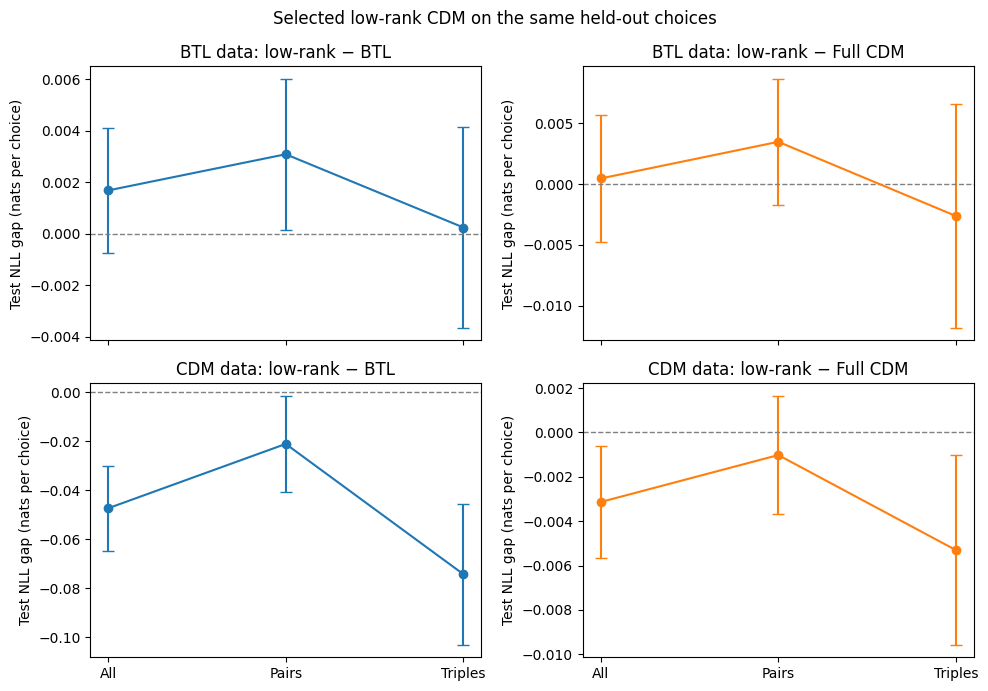

In [34]:
# Plot paired test NLL gaps for both data sources and both comparators.
started_at = perf_counter()
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
groups = ["All", "Pairs", "Triples"]

for row, source in enumerate(("BTL", "CDM")):
    for col, comparator in enumerate(("BTL", "Full CDM")):
        ax = axes[row, col]
        values = (
            low_rank_gap_summary.loc[
                (low_rank_gap_summary["Source"] == source)
                & (low_rank_gap_summary["Comparison"]
                   == f"Low-rank - {comparator}")
            ]
            .set_index("Group")
            .loc[groups]
        )

        ax.errorbar(
            range(3),
            values["Mean gap"],
            yerr=1.96 * values["SE"],
            fmt="o-",
            capsize=4,
            color="tab:blue" if comparator == "BTL" else "tab:orange",
        )
        ax.axhline(0, color="gray", linestyle="--", linewidth=1)
        ax.set_title(f"{source} data: low-rank − {comparator}")
        ax.set_xticks(range(3), groups)
        ax.set_ylabel("Test NLL gap (nats per choice)")

fig.suptitle("Selected low-rank CDM on the same held-out choices")
fig.tight_layout()

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    FIGURE_DIR / "04_low_rank_paired_test_nll_gaps.png",
    dpi=200, bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "04_low_rank_paired_test_nll_gaps.pdf",
    bbox_inches="tight"
)

stage = "Low-rank paired test NLL figure"
runtime_log = pd.concat(
    [
        runtime_log[runtime_log["Stage"] != stage],
        pd.DataFrame([{
            "Stage": stage,
            "Data source": "Both",
            "Model": "Selected low-rank CDM vs BTL and full CDM",
            "Elapsed seconds": perf_counter() - started_at,
            "Seed": SEED,
            "Items": N_ITEMS,
            "Device": str(DEVICE),
        }]),
    ],
    ignore_index=True,
)
runtime_log.to_csv(LOG_DIR / "04_runtime_log.csv", index=False)

plt.show()